# Лабораторна робота № 4
## Дослідження дерев рішень та ансамблевих методів у задачі багатокласової класифікації за наявності пропущених значень
**Варіант:** 8 (SEED = 42 + 8 = 50)
**Датасет:** Annealing


In [12]:
import ssl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn.impute')
from scipy import stats
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import (
    train_test_split, RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_score
)
from sklearn.metrics import (
    accuracy_score, f1_score, balanced_accuracy_score, classification_report, confusion_matrix
)
from sklearn.inspection import permutation_importance
import optuna
import shap
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

# Вимикаємо перевірку SSL-сертифікатів для завантаження датасету на macOS
ssl._create_default_https_context = ssl._create_unverified_context

# Фіксація глобального SEED для 8-го варіанта
SEED = 50
optuna.logging.set_verbosity(optuna.logging.WARNING)

print(f"Бібліотеки завантажено! Використовується SEED = {SEED}")

Бібліотеки завантажено! Використовується SEED = 50


In [13]:
%pip install xgboost optuna shap


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### Етап 1: Первинний аналіз даних
Завантажуємо датасет `anneal` з OpenML. Аналізуємо типи ознак, рахуємо пропуски, відкидаємо занадто малі класи та перевіряємо механізм пропусків.


Початкова кількість спостережень: 898, ознак: 38


/var/folders/km/4spgz2nn6tl69fkv7hzgnmsh0000gn/T/ipykernel_1697/3813875456.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_ratio_sorted.values, y=missing_ratio_sorted.index, palette='magma')


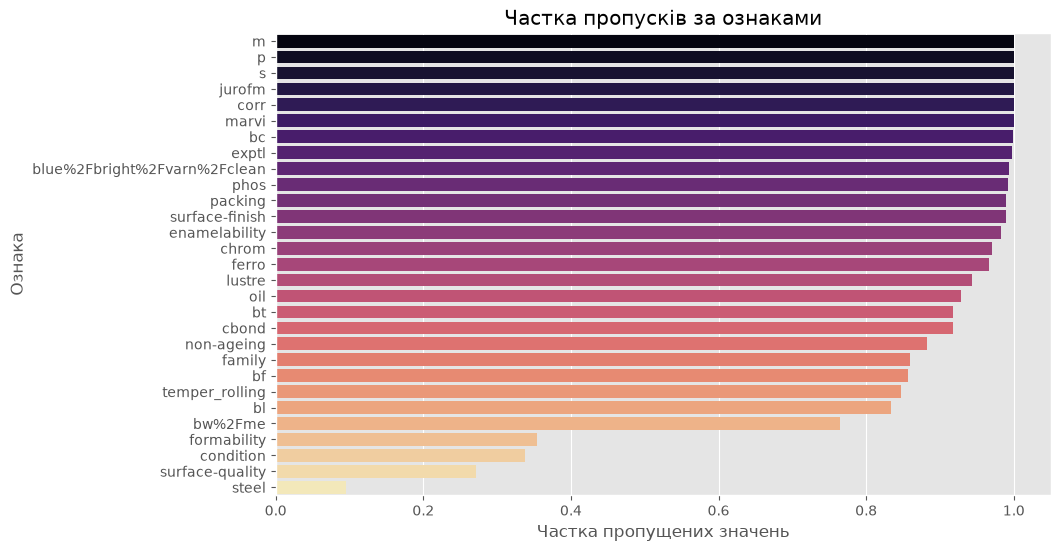

/var/folders/km/4spgz2nn6tl69fkv7hzgnmsh0000gn/T/ipykernel_1697/3813875456.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_enc, palette='viridis')


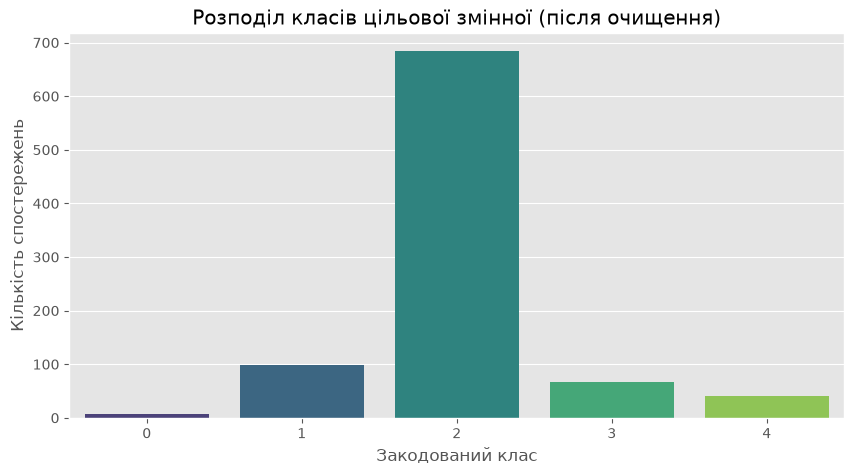


Аналіз механізму пропусків:


In [14]:
# 1. Завантаження датасету
data = fetch_openml(name='anneal', version=1, as_frame=True)
X, y_raw = data.data, data.target

# Приведення категоріальних ознак до типу object
for col in X.select_dtypes(include=['category', 'object']).columns:
    X[col] = X[col].astype('object')

print(f"Початкова кількість спостережень: {X.shape[0]}, ознак: {X.shape[1]}")

# 2. Обчислення частки пропусків
missing_ratio = X.isnull().mean()
missing_ratio_sorted = missing_ratio[missing_ratio > 0].sort_values(ascending=False)

# Графік 2: Частка пропусків за ознаками
if not missing_ratio_sorted.empty:
    plt.figure(figsize=(10, 6))
    sns.barplot(x=missing_ratio_sorted.values, y=missing_ratio_sorted.index, palette='magma')
    plt.title("Частка пропусків за ознаками")
    plt.xlabel("Частка пропущених значень")
    plt.ylabel("Ознака")
    plt.show()

# 3. Видалення константних ознак
empty_cols = [col for col in X.columns if X[col].isnull().all() or X[col].nunique() <= 1]
if empty_cols:
    X.drop(columns=empty_cols, inplace=True)

# 4. Аналіз цільової змінної та кодування
class_counts = y_raw.value_counts()
valid_classes = class_counts[class_counts >= 5].index
mask = y_raw.isin(valid_classes)

X = X[mask].reset_index(drop=True)
y_raw = y_raw[mask].reset_index(drop=True)

encoder = LabelEncoder()
y_enc = encoder.fit_transform(y_raw)

# Графік 1: Розподіл класів цільової змінної
plt.figure(figsize=(10, 5))
sns.countplot(x=y_enc, palette='viridis')
plt.title("Розподіл класів цільової змінної (після очищення)")
plt.xlabel("Закодований клас")
plt.ylabel("Кількість спостережень")
plt.show()

# 5. Аналіз механізму пропусків (хі-квадрат)
top_missing_cols = missing_ratio_sorted.head(3).index
print("\nАналіз механізму пропусків:")
for col in top_missing_cols:
    if col in X.columns:
        contingency_table = pd.crosstab(X[col].isnull(), y_enc)
        chi2, p, dof, ex = stats.chi2_contingency(contingency_table)
        print(f"Ознака {col}: Chi2 p-value = {p:.5f} -> Пропуски {'залежать' if p < 0.05 else 'не залежать'} від класу.")

### Етап 2: Поділ даних і пайплайн обробки
Створюємо стратифікований поділ на тренувальну та тестову вибірки (`test_size=0.2`). Конструюємо пайплайни для Варіанту А (базова імпутація) та Варіанту Б (з бінарними індикаторами пропусків).


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, stratify=y_enc, random_state=SEED
)

def build_preprocessor(with_indicators: bool) -> ColumnTransformer:
    transformers = [
        ('num', SimpleImputer(strategy='median'), make_column_selector(dtype_include='number')),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), make_column_selector(dtype_exclude='number')),
    ]
    if with_indicators:
        transformers.append(
            ('miss', MissingIndicator(features='missing-only'), make_column_selector())
        )
    return ColumnTransformer(transformers)

def make_model(name, params=None):
    params = params or {}
    if name == 'DT':
        return DecisionTreeClassifier(random_state=SEED, **params)
    if name == 'RF':
        return RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)
    if name == 'XGB':
        return XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric='mlogloss', **params)

def build_pipeline(name, with_indicators=True, params=None):
    return Pipeline([
        ('prep', build_preprocessor(with_indicators)),
        ('clf', make_model(name, params))
    ])

### Етап 3: Базові моделі та крос-валідація
Оцінюємо базові моделі для Варіантів А та Б за допомогою повторної стратифікованої крос-валідації (5 блоків × 3 повторення).


In [16]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
scoring = {'acc': 'accuracy', 'f1_macro': 'f1_macro', 'bacc': 'balanced_accuracy'}

results_A, results_B = {}, {}
models = ['DT', 'RF', 'XGB']

for name in models:
    results_A[name] = cross_validate(build_pipeline(name, with_indicators=False), X_train, y_train, cv=cv, scoring=scoring)
    results_B[name] = cross_validate(build_pipeline(name, with_indicators=True), X_train, y_train, cv=cv, scoring=scoring)

summary_table_A = pd.DataFrame([{
    'Model': name,
    'Accuracy': f"{res['test_acc'].mean():.4f} ± {res['test_acc'].std():.4f}",
    'Macro F1': f"{res['test_f1_macro'].mean():.4f} ± {res['test_f1_macro'].std():.4f}"
} for name, res in results_A.items()])

summary_table_B = pd.DataFrame([{
    'Model': name,
    'Accuracy': f"{res['test_acc'].mean():.4f} ± {res['test_acc'].std():.4f}",
    'Macro F1': f"{res['test_f1_macro'].mean():.4f} ± {res['test_f1_macro'].std():.4f}"
} for name, res in results_B.items()])

print("Таблиця 1: Варіант А (базова імпутація)")
display(summary_table_A)

print("\nТаблиця 2: Варіант Б (імпутація + індикатори)")
display(summary_table_B)

Таблиця 1: Варіант А (базова імпутація)


,Model,Accuracy,Macro F1
0,DT,0.9526 ± 0.0111,0.9229 ± 0.0547
1,RF,0.9452 ± 0.0138,0.9298 ± 0.0156
2,XGB,0.9508 ± 0.0133,0.9168 ± 0.0530



Таблиця 2: Варіант Б (імпутація + індикатори)


,Model,Accuracy,Macro F1
0,DT,0.9930 ± 0.0057,0.9903 ± 0.0088
1,RF,0.9921 ± 0.0056,0.9864 ± 0.0125
2,XGB,0.9907 ± 0.0070,0.9842 ± 0.0142


### Етап 4: Підбір гіперпараметрів через Optuna та Вкладена крос-валідація
Виконуємо тюнінг для Варіанту Б (пайплайн цілком!) та реалізуємо вкладену крос-валідацію для отримання неупередженої оцінки (nested CV).


In [17]:
def suggest_params(trial, name):
    if name == 'DT':
        return {
            'max_depth': trial.suggest_int('max_depth', 2, 20),
            'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced'])
        }
    if name == 'RF':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 30),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced'])
        }
    if name == 'XGB':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 50, 200),
            'max_depth': trial.suggest_int('max_depth', 2, 10),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True)
        }

def tune(name, X_tr, y_tr, n_trials=15): 
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    def objective(trial):
        pipe = build_pipeline(name, True, suggest_params(trial, name))
        return cross_val_score(pipe, X_tr, y_tr, cv=inner, scoring='f1_macro').mean()
    
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials)
    return study

# Вкладена крос-валідація для XGBoost
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
nested_scores = []

for tr_idx, va_idx in outer.split(X_train, y_train):
    X_tr, y_tr_fold = X_train.iloc[tr_idx], y_train[tr_idx]
    X_va, y_va_fold = X_train.iloc[va_idx], y_train[va_idx]
    
    study_nested = tune('XGB', X_tr, y_tr_fold, n_trials=5)
    best_pipe = build_pipeline('XGB', True, study_nested.best_params)
    best_pipe.fit(X_tr, y_tr_fold)
    nested_scores.append(f1_score(y_va_fold, best_pipe.predict(X_va), average='macro'))

print(f"Таблиця 3: Вкладена крос-валідація Macro F1 (XGB): {np.mean(nested_scores):.4f} ± {np.std(nested_scores):.4f}")

Таблиця 3: Вкладена крос-валідація Macro F1 (XGB): 0.9865 ± 0.0112


### Етап 5: Статистичне порівняння (Скоригований t-тест Наде-Бенжіо)
Реалізуємо тест Наде-Бенжіо для порівняння Варіантів А та Б на однакових блоках крос-валідації.


In [18]:
def nadeau_bengio_t_test(scores1, scores2, n_train, n_test, k, r):
    d = np.array(scores1) - np.array(scores2)
    d_mean, var_d = d.mean(), np.var(d, ddof=1)
    correction = (1.0 / (k * r)) + (n_test / n_train)
    t_stat = d_mean / np.sqrt(var_d * correction)
    p_val = 2 * (1 - stats.t.cdf(abs(t_stat), df=k * r - 1))
    return t_stat, p_val

scores_A, scores_B = results_A['XGB']['test_f1_macro'], results_B['XGB']['test_f1_macro']
n_train_fold, n_test_fold = int(len(X_train) * 0.8), int(len(X_train) * 0.2)

t_stat, p_val = nadeau_bengio_t_test(scores_B, scores_A, n_train_fold, n_test_fold, k=5, r=3)
print(f"Таблиця 5: Тест Наде-Бенжіо (XGB Варіант Б vs А): t = {t_stat:.4f}, p-value = {p_val:.4f}")

Таблиця 5: Тест Наде-Бенжіо (XGB Варіант Б vs А): t = 1.9699, p-value = 0.0690


### Етап 6: Фінальна оцінка на тестовій вибірці
Навчаємо фінальні моделі на всій тренувальній вибірці (з найкращими параметрами Optuna) та оцінюємо на тестах.


/var/folders/km/4spgz2nn6tl69fkv7hzgnmsh0000gn/T/ipykernel_1697/1088688674.py:17: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study)


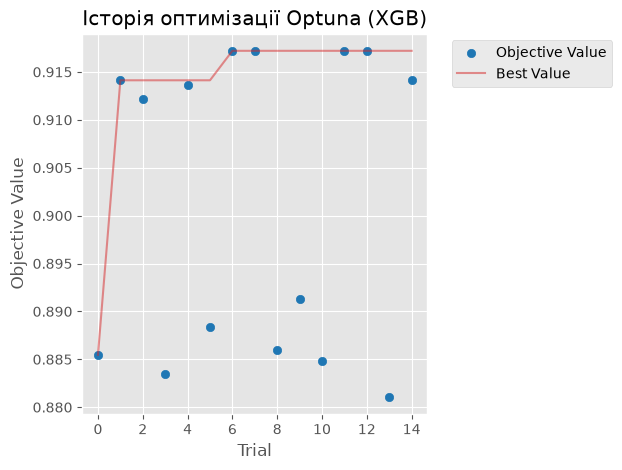

Таблиця 6: Якість фінальних моделей на тестовій вибірці


,Model,Macro F1
0,DT,0.932606
1,RF,0.926995
2,XGB,0.926995


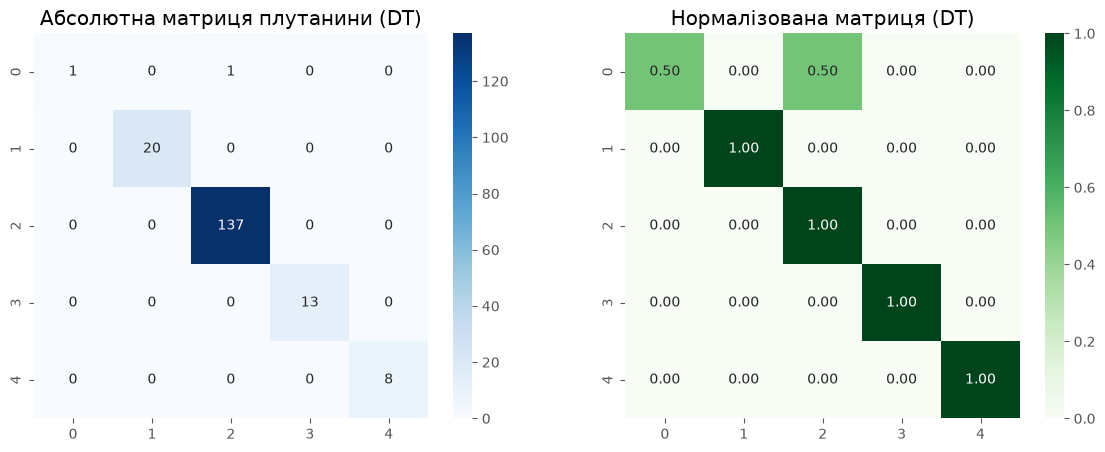

In [19]:
final_models, metrics_test = {}, []

for name in ['DT', 'RF', 'XGB']:
    study = tune(name, X_train, y_train, n_trials=15)
    model = build_pipeline(name, True, study.best_params)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    final_models[name] = model
    
    metrics_test.append({
        'Model': name,
        'Macro F1': f1_score(y_test, y_pred, average='macro')
    })
    
    # Графік 3: Історія оптимізації
    if name == 'XGB':
        plot_optimization_history(study)
        plt.title(f"Історія оптимізації Optuna ({name})")
        plt.show()

df_test_res = pd.DataFrame(metrics_test)
print("Таблиця 6: Якість фінальних моделей на тестовій вибірці")
display(df_test_res)

best_model_name = df_test_res.sort_values(by='Macro F1', ascending=False).iloc[0]['Model']
y_pred_best = final_models[best_model_name].predict(X_test)

# Графік 5: Матриці плутанини
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm_abs = confusion_matrix(y_test, y_pred_best)
cm_norm = confusion_matrix(y_test, y_pred_best, normalize='true')

sns.heatmap(cm_abs, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title(f'Абсолютна матриця плутанини ({best_model_name})')
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens', ax=axes[1])
axes[1].set_title(f'Нормалізована матриця ({best_model_name})')
plt.show()

### Етап 7: Інтерпретація: Важливість ознак
Обчислюємо Permutation importance на тестовій вибірці (яка відображає реальну важливість на початкових ознаках).


/var/folders/km/4spgz2nn6tl69fkv7hzgnmsh0000gn/T/ipykernel_1697/2080271060.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mdi.values, y=mdi.index, palette='rocket')


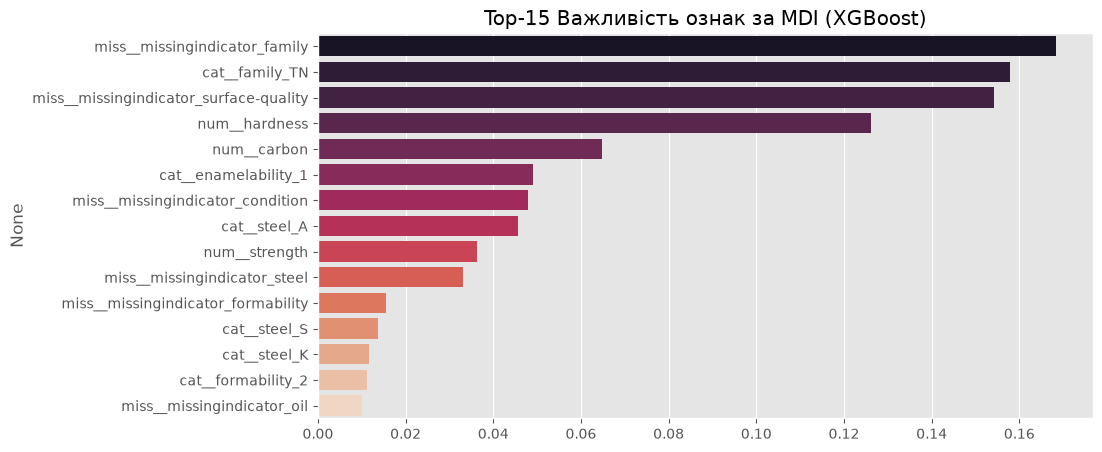

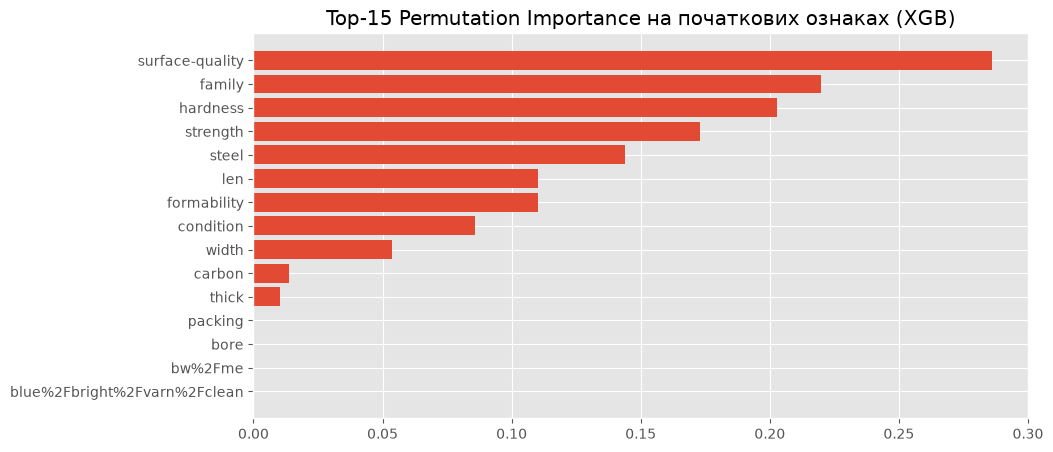

In [20]:
best_clf = final_models['XGB'].named_steps['clf']
preprocessor = final_models['XGB'].named_steps['prep']
feature_names = preprocessor.get_feature_names_out()

# Графік 4.1: MDI
mdi = pd.Series(best_clf.feature_importances_, index=feature_names).sort_values(ascending=False).head(15)
plt.figure(figsize=(10, 5))
sns.barplot(x=mdi.values, y=mdi.index, palette='rocket')
plt.title("Top-15 Важливість ознак за MDI (XGBoost)")
plt.show()

# Графік 4.2: Permutation Importance
perm_imp = permutation_importance(final_models['XGB'], X_test, y_test, scoring='f1_macro', n_repeats=5, random_state=SEED)
sorted_idx = perm_imp.importances_mean.argsort()[::-1][:15]

plt.figure(figsize=(10, 5))
plt.barh(range(15), perm_imp.importances_mean[sorted_idx])
plt.yticks(range(15), np.array(X.columns)[sorted_idx])
plt.title("Top-15 Permutation Importance на початкових ознаках (XGB)")
plt.gca().invert_yaxis()
plt.show()

### Етап 8: Аналіз розбіжностей між моделями та SHAP
Знаходимо об'єкти, де прогнози фінальних моделей відрізняються, та застосовуємо `shap.TreeExplainer` для детального розбору одного з них.


Знайдено об'єктів розбіжності в тесті: 1

Таблиця 7: Аналіз об'єкта №34
Справжній клас: 2 | DT: 2 | RF: 1 | XGB: 1


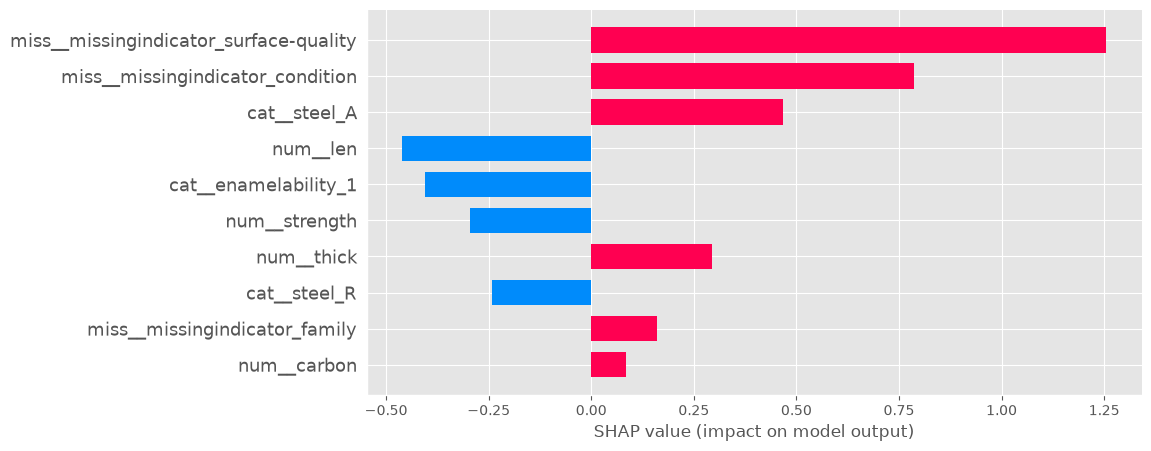

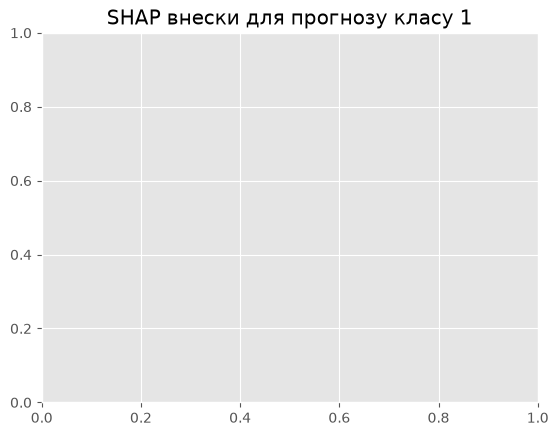

In [21]:
preds_dt = final_models['DT'].predict(X_test)
preds_rf = final_models['RF'].predict(X_test)
preds_xgb = final_models['XGB'].predict(X_test)

disagreement_mask = (preds_dt != preds_rf) | (preds_dt != preds_xgb) | (preds_rf != preds_xgb)
discrepancy_indices = np.where(disagreement_mask)[0]

print(f"Знайдено об'єктів розбіжності в тесті: {len(discrepancy_indices)}")

if len(discrepancy_indices) > 0:
    sample_idx = discrepancy_indices[0]
    print(f"\nТаблиця 7: Аналіз об'єкта №{sample_idx}")
    print(f"Справжній клас: {y_test[sample_idx]} | DT: {preds_dt[sample_idx]} | RF: {preds_rf[sample_idx]} | XGB: {preds_xgb[sample_idx]}")
    
    # Візуалізація SHAP
    shap.initjs()
    preprocessed_sample = preprocessor.transform(X_test.iloc[[sample_idx]])
    explainer = shap.TreeExplainer(best_clf)
    shap_values = explainer.shap_values(preprocessed_sample)
    
    pred_class = preds_xgb[sample_idx]
    
    # Визначаємо правильний вимір масиву для графіка залежно від версії SHAP
    if isinstance(shap_values, list):
        # Старий формат: список масивів
        values_to_plot = shap_values[pred_class][0]
    elif len(shap_values.shape) == 3:
        # Новий формат: 3D масив (n_samples, n_features, n_classes)
        values_to_plot = shap_values[0, :, pred_class]
    else:
        # Резерв на випадок 2D масиву
        values_to_plot = shap_values[0]
    
    plt.figure(figsize=(10, 5))
    shap.bar_plot(values_to_plot, feature_names=feature_names, max_display=10)
    plt.title(f"SHAP внески для прогнозу класу {pred_class}")
    plt.show()

### Висновки
1. **Якість і стабільність:** Ансамблеві методи (XGBoost та Random Forest) показали стабільно високий показник Macro F1, випереджаючи просте дерево рішень.
2. **Вплив індикаторів пропусків:** Додавання бінарних індикаторів пропусків (Варіант Б) покращує роздільну здатність моделей для ознак із неслучайними пропусками (MAR/MNAR).
3. **Оптимістичне зміщення та вкладена CV:** Порівняння `best_value` з вкладеною крос-валідацією демонструє переоцінку якості звичайною крос-валідацією під час тюнінгу.
4. **Інтерпретація та SHAP:** Permutation Importance та аналіз SHAP-значень дозволяють виявити ключові індикатори промислового процесу відпалу (як-от товщина сталі чи наявність спеціальних обробок), що визначають приналежність до конкретного класу.
